Archivo cargado correctamente.


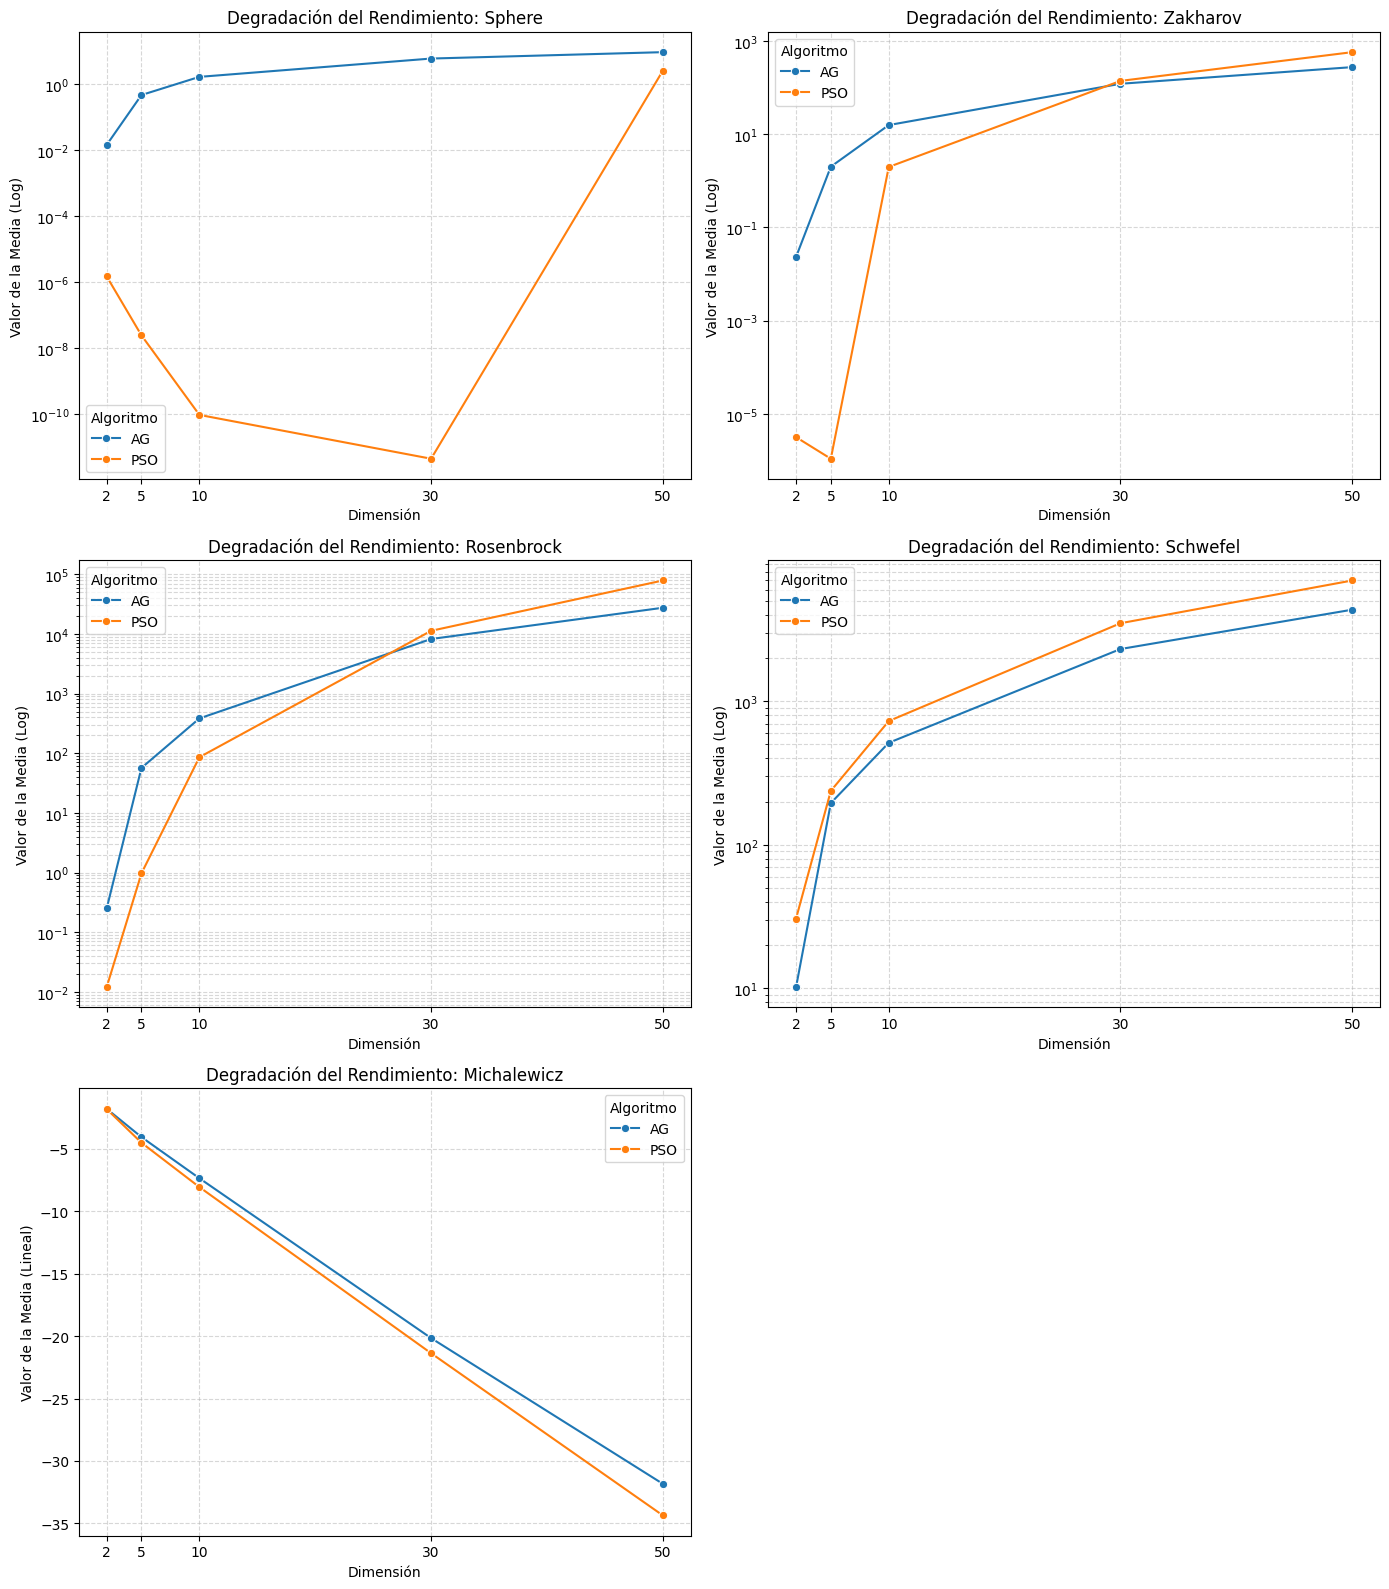

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Leer el archivo CSV generado en la celda anterior
try:
    df = pd.read_csv('resultados_optimizacion.csv')
    print("Archivo cargado correctamente.")
except FileNotFoundError:
    print("Error: No se encontró 'resultados_optimizacion.csv'. Asegúrate de haber guardado el archivo en la celda anterior.")

# 2. Limpieza: Extraer el valor numérico de la Media
# El CSV guardó el texto "Media ± DE", así que cortamos el texto antes del símbolo "±"
df['Media Numérica'] = df['Media ± DE'].apply(lambda x: float(str(x).split('±')[0].strip()))

# 3. Crear las 5 gráficas de líneas
funciones = df['Función'].unique()
fig, axes = plt.subplots(3, 2, figsize=(14, 16))
axes = axes.flatten()

for i, func in enumerate(funciones):
    ax = axes[i]
    df_func = df[df['Función'] == func]
    
    # Graficar la línea
    sns.lineplot(data=df_func, x='Dimensión', y='Media Numérica', hue='Algoritmo', marker='o', ax=ax)
    
    ax.set_title(f'Degradación del Rendimiento: {func}')
    ax.set_xticks([2, 5, 10, 30, 50])
    
    # Aplicar escala logarítmica a todas menos a Michalewicz (porque tiene valores negativos)
    if func != 'Michalewicz':
        ax.set_yscale('log')
        ax.set_ylabel('Valor de la Media (Log)')
    else:
        ax.set_ylabel('Valor de la Media (Lineal)')
        
    ax.grid(True, which="both", ls="--", alpha=0.5)

# Eliminar el 6to cuadro que sobra (porque son 5 funciones)
fig.delaxes(axes[5])

plt.tight_layout()
plt.show()

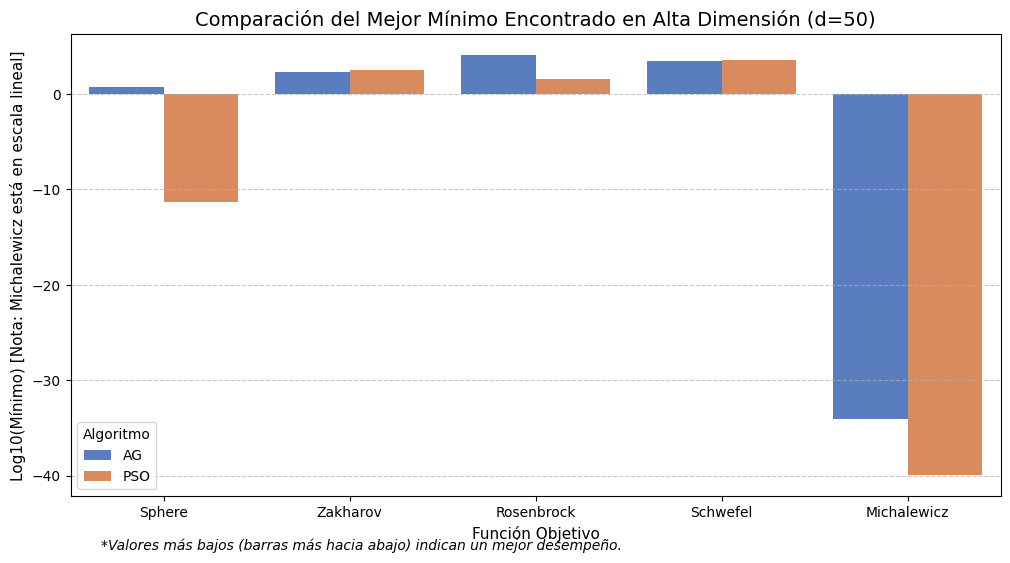

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# 1. Cargar datos
df = pd.read_csv('resultados_optimizacion.csv')

# 2. Filtrar solo el escenario más complejo: 50 dimensiones
df_50d = df[df['Dimensión'] == 50].copy()

# 3. Configurar la gráfica de barras
plt.figure(figsize=(12, 6))

# Usamos barplot de seaborn. Como la diferencia de escalas entre funciones es masiva 
# (ej. Sphere vs Rosenbrock), graficaremos el logaritmo del Mínimo para que se aprecie visualmente,
# excepto para Michalewicz que es negativo.

# Ajuste matemático solo para visualización
def safe_log(x, func_name):
    if func_name == 'Michalewicz':
        return x # Michalewicz se queda igual
    return np.log10(x) if x > 0 else 0

df_50d['Log_Mínimo'] = df_50d.apply(lambda row: safe_log(row['Mínimo'], row['Función']), axis=1)

sns.barplot(data=df_50d, x='Función', y='Log_Mínimo', hue='Algoritmo', palette='muted')

plt.title('Comparación del Mejor Mínimo Encontrado en Alta Dimensión (d=50)', fontsize=14)
plt.ylabel('Log10(Mínimo) [Nota: Michalewicz está en escala lineal]', fontsize=11)
plt.xlabel('Función Objetivo', fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Agregar una nota aclaratoria en la imagen para el profesor
plt.figtext(0.15, 0.02, '*Valores más bajos (barras más hacia abajo) indican un mejor desempeño.', 
            fontsize=10, style='italic')

plt.show()

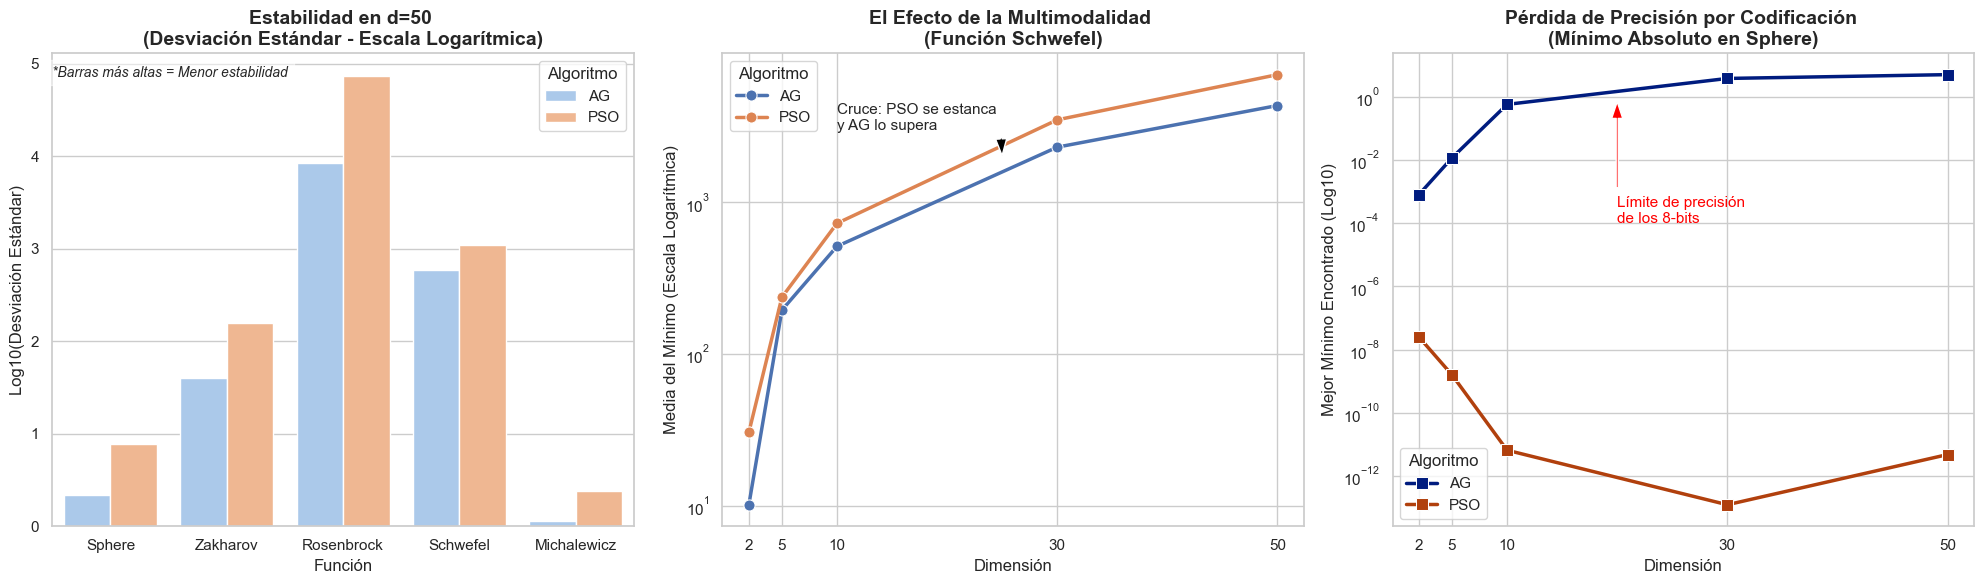

In [3]:
import pandas as pd
import io
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Tus datos crudos
datos_csv = """Función,Dimensión,Algoritmo,Mínimo,Máximo,Media ± DE,Mediana
Sphere,2,AG,0.0008062868127643243,0.03950805382545189,1.4435e-02 ± 1.2170e-02,0.010481728565936215
Sphere,2,PSO,2.477397244963685e-08,1.3636729484366728e-05,1.4937e-06 ± 2.5494e-06,6.897195076564555e-07
Sphere,5,AG,0.011691158785082702,1.1662938746635905,4.6633e-01 ± 2.8421e-01,0.4341854486735867
Sphere,5,PSO,1.5719052063725131e-09,9.509875037039987e-08,2.4496e-08 ± 2.1479e-08,1.73018180735813e-08
Sphere,10,AG,0.5748824975009615,2.9131142545174935,1.6539e+00 ± 6.1038e-01,1.5198506420607463
Sphere,10,PSO,6.495306947237991e-12,3.8233140288032054e-10,9.5604e-11 ± 9.7902e-11,5.895102864526164e-11
Sphere,30,AG,3.811317763936948,8.923176156862745,5.9330e+00 ± 1.1981e+00,5.620625371780087
Sphere,30,PSO,1.221836975034963e-13,2.3795917601484592e-11,4.4988e-12 ± 5.8192e-12,2.431263084108409e-12
Sphere,50,AG,5.028810851211073,15.036442771241832,9.2635e+00 ± 2.1937e+00,9.03766888427528
Sphere,50,PSO,4.735528063023805e-12,26.214400000106885,2.5369e+00 ± 7.7503e+00,2.9079773423649457e-10
Zakharov,2,AG,0.004326007830365985,0.07012981765065095,2.3355e-02 ± 1.9036e-02,0.017301038062283825
Zakharov,2,PSO,3.811110830377721e-08,1.2842343024598862e-05,3.1720e-06 ± 3.2049e-06,1.774138102001191e-06
Zakharov,5,AG,0.07399710851163199,4.659753984027969,2.0111e+00 ± 1.2392e+00,1.805055016103731
Zakharov,5,PSO,7.415954136977046e-08,6.201903023417298e-06,1.0935e-06 ± 1.2462e-06,7.845080783322204e-07
Zakharov,10,AG,6.161456400186768,31.8434922055531,1.5713e+01 ± 6.2922e+00,15.609595191628447
Zakharov,10,PSO,3.6289993389385513e-06,31.58031225416203,1.9844e+00 ± 7.5580e+00,0.00010471341536442544
Zakharov,30,AG,74.19484096813972,159.12665078243793,1.2075e+02 ± 1.8757e+01,123.19917520743297
Zakharov,30,PSO,16.84450536432676,323.75887920007006,1.3918e+02 ± 8.8194e+01,103.0338297308162
Zakharov,50,AG,213.37642404305365,415.85695813029037,2.7488e+02 ± 3.9879e+01,276.2013782461895
Zakharov,50,PSO,291.7894501376097,905.7400953483193,5.7571e+02 ± 1.5849e+02,552.9927369864109
Rosenbrock,2,AG,0.0,0.8082877360184826,2.5014e-01 ± 1.9264e-01,0.1834867877539761
Rosenbrock,2,PSO,1.8243519632256885e-06,0.2120140441286893,1.2042e-02 ± 3.7894e-02,0.002632484412271225
Rosenbrock,5,AG,11.042612037691098,130.71547275535488,5.6746e+01 ± 2.6811e+01,56.507022186037
Rosenbrock,5,PSO,0.008234099814820317,9.463653780267682,9.6937e-01 ± 1.5796e+00,0.7645274896612774
Rosenbrock,10,AG,131.07989607404136,864.5573927515228,3.8343e+02 ± 1.9894e+02,305.43873995761544
Rosenbrock,10,PSO,0.3984736183523212,2504.5247248041787,8.5782e+01 ± 4.4160e+02,5.224139470403764
Rosenbrock,30,AG,1919.93364543049,24511.02953748158,8.2193e+03 ± 5.7460e+03,7450.576657367606
Rosenbrock,30,PSO,10.97618147445648,117027.05614806926,1.1276e+04 ± 2.6772e+04,81.59717932579561
Rosenbrock,50,AG,11644.673734749347,46744.721950168205,2.7459e+04 ± 8.4999e+03,27625.119754313277
Rosenbrock,50,PSO,33.61640950372353,277403.68996996206,7.8657e+04 ± 7.4362e+04,58053.153099102696
Schwefel,2,AG,0.09086091009351094,44.47207953704128,1.0191e+01 ± 1.1665e+01,6.629666412209531
Schwefel,2,PSO,3.903087258549931e-05,119.3565913108514,3.0610e+01 ± 5.1866e+01,0.0009291740549315364
Schwefel,5,AG,32.43741431244689,346.3790520668722,1.9529e+02 ± 8.6612e+01,196.33808427298277
Schwefel,5,PSO,0.0004055185099787195,476.7875211849373,2.3742e+02 ± 1.4158e+02,236.8767447267196
Schwefel,10,AG,178.0803340519774,789.6942256227653,5.1378e+02 ± 1.6490e+02,534.4222094524289
Schwefel,10,PSO,0.005342116318388435,1188.9346519913456,7.2816e+02 ± 2.7128e+02,713.6642539906989
Schwefel,30,AG,1765.5558073856937,3080.426234899016,2.3135e+03 ± 3.4908e+02,2215.4483404794555
Schwefel,30,PSO,2236.6817321700055,5008.89295475481,3.5004e+03 ± 7.6900e+02,3353.857561856341
Schwefel,50,AG,3005.7702719606095,5397.078112214462,4.3502e+03 ± 5.8410e+02,4346.012024405845
Schwefel,50,PSO,3437.834016644483,9301.387163642132,6.9507e+03 ± 1.0909e+03,7110.444491239976
Michalewicz,2,AG,-1.799682372454007,-1.6730377505785636,-1.7803e+00 ± 2.7287e-02,-1.7876312285115168
Michalewicz,2,PSO,-1.8013033653282198,-1.8009954084888546,-1.8013e+00 ± 5.4054e-05,-1.8013019530129997
Michalewicz,5,AG,-4.358735015822057,-3.606563129942412,-4.0448e+00 ± 2.0441e-01,-4.050592324301592
Michalewicz,5,PSO,-4.687658127769749,-3.749195726629294,-4.4963e+00 ± 2.7315e-01,-4.645827565275997
Michalewicz,10,AG,-8.23096577704739,-6.570759135281785,-7.3455e+00 ± 4.3032e-01,-7.342455890344227
Michalewicz,10,PSO,-9.577927133143389,-6.1557315748737995,-8.0527e+00 ± 7.7564e-01,-7.93144692426032
Michalewicz,30,AG,-21.530814527055355,-18.99108548017527,-2.0160e+01 ± 6.2944e-01,-20.188721259851892
Michalewicz,30,PSO,-25.2917631305966,-17.350196586784367,-2.1371e+01 ± 1.7343e+00,-21.43038701464603
Michalewicz,50,AG,-34.02917007068951,-28.9077032002752,-3.1838e+01 ± 1.1400e+00,-31.866870549548352
Michalewicz,50,PSO,-39.93390040010948,-30.208650270204107,-3.4369e+01 ± 2.3987e+00,-33.6498879906773"""

df = pd.read_csv(io.StringIO(datos_csv))

# Extraer Media y Desviación Estándar a columnas separadas
df['Media Numérica'] = df['Media ± DE'].apply(lambda x: float(x.split('±')[0].strip()))
df['Desviacion_Estandar'] = df['Media ± DE'].apply(lambda x: float(x.split('±')[1].strip()))

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# --- GRÁFICA 1: Estabilidad (Desviación Estándar en 50D) para Diapositiva 4 ---
df_50d = df[df['Dimensión'] == 50].copy()
# Aplicamos log10 a la desviación (excepto Michalewicz para evitar errores)
df_50d['Log_DE'] = df_50d.apply(lambda row: np.log10(row['Desviacion_Estandar']) if row['Desviacion_Estandar'] > 0 else 0, axis=1)

sns.barplot(data=df_50d, x='Función', y='Log_DE', hue='Algoritmo', ax=axes[0], palette='pastel')
axes[0].set_title('Estabilidad en d=50 \n(Desviación Estándar - Escala Logarítmica)', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Log10(Desviación Estándar)')
axes[0].text(-0.5, axes[0].get_ylim()[1]*0.95, '*Barras más altas = Menor estabilidad', fontsize=10, style='italic', bbox=dict(facecolor='white', alpha=0.5))

# --- GRÁFICA 2: Impacto Multimodalidad (Zoom a Schwefel) para Diapositiva 6 ---
df_schwefel = df[df['Función'] == 'Schwefel']
sns.lineplot(data=df_schwefel, x='Dimensión', y='Media Numérica', hue='Algoritmo', marker='o', ax=axes[1], palette='deep', linewidth=2.5, markersize=8)
axes[1].set_title('El Efecto de la Multimodalidad \n(Función Schwefel)', fontsize=14, fontweight='bold')
axes[1].set_yscale('log')
axes[1].set_xticks([2, 5, 10, 30, 50])
axes[1].set_ylabel('Media del Mínimo (Escala Logarítmica)')
axes[1].annotate('Cruce: PSO se estanca \ny AG lo supera', xy=(25, 2000), xytext=(10, 3000),
            arrowprops=dict(facecolor='black', shrink=0.05, width=1.5, headwidth=8), fontsize=11)

# --- GRÁFICA 3: Pérdida de Precisión AG (Zoom a Mínimos de Sphere) para Diapositiva 7 ---
df_sphere = df[df['Función'] == 'Sphere']
sns.lineplot(data=df_sphere, x='Dimensión', y='Mínimo', hue='Algoritmo', marker='s', ax=axes[2], palette='dark', linewidth=2.5, markersize=8)
axes[2].set_title('Pérdida de Precisión por Codificación \n(Mínimo Absoluto en Sphere)', fontsize=14, fontweight='bold')
axes[2].set_yscale('log')
axes[2].set_xticks([2, 5, 10, 30, 50])
axes[2].set_ylabel('Mejor Mínimo Encontrado (Log10)')
axes[2].annotate('Límite de precisión\nde los 8-bits', xy=(20, 1), xytext=(20, 1e-4),
            arrowprops=dict(facecolor='red', shrink=0.05, width=1.5, headwidth=8), fontsize=11, color='red')

plt.tight_layout()
plt.show()

# Opcional: Guardar la imagen en tu computadora
# fig.savefig('graficas_presentacion.png', dpi=300)